# Step 5 – Dimensionality Reduction: PCA, t-SNE and UMAP

This step reduces the 34-dimensional clustering feature matrix to fewer dimensions to understand the structure of borrower segments.

**Input feature matrix**

- Observations: 1,347,681
- Features: 34
- Matrix type: SciPy CSR sparse matrix
- Numerical features: 4 scaled variables
- Categorical features: one-hot encoded variables

**Techniques**

| Technique | Purpose |
|---|---|
| PCA | Reduce dimensions while retaining as much variance as possible |
| t-SNE | Visualize local similarities between borrowers |
| UMAP | Visualize local and broader data structure efficiently |

**Important:** `Default` is not included in dimensionality reduction, so that borrower patterns are discovered without the known default outcome. It is used only to colour the plots.

With 1.35 million observations, t-SNE and UMAP on the full dataset would be computationally expensive. They are run on a representative 5,000-record sample for visualization, while PCA is fitted to the full dataset.

## Step 5.1 – Apply PCA

PCA cannot efficiently process a sparse CSR matrix directly. `IncrementalPCA` is used instead: it works in batches and avoids converting the entire dataset to a dense matrix at once.

Ten principal components are retained initially, and the variance they explain is examined.

**Prerequisite:** the next two code cells load the cleaned data and recreate the clustering matrix from Step 4 (`X_cluster_scaled`).

In [3]:
import pandas as pd
from pathlib import Path

DATA_PATH = Path(
    r"D:\HCL_PROJECTS\Credit Portfolio Segmentation and Risk Pattern Analysis Project-3\step2_outputs\cleaned_credit_portfolio.csv"
)

df = pd.read_csv(DATA_PATH)

print("Dataset shape:", df.shape)
display(df.head())

Dataset shape: (1347681, 15)


,id,issue_d,revenue,dti_n,loan_amnt,fico_n,experience_c,emp_length,purpose,home_ownership_n,addr_state,Default,revenue_log,dti_capped,dti_extreme
0,68407277,Dec-2015,55000.0,5.91,3600,677.0,1,10+ years,debt_consolidation,MORTGAGE,PA,0,10.915107,5.91,0
1,68355089,Dec-2015,65000.0,16.06,24700,717.0,1,10+ years,small_business,MORTGAGE,SD,0,11.082158,16.06,0
2,68341763,Dec-2015,71000.0,13.85,20000,697.0,1,10+ years,home_improvement,MORTGAGE,IL,0,11.170449,13.85,0
3,68476807,Dec-2015,104433.0,25.37,10400,697.0,1,3 years,major_purchase,MORTGAGE,PA,0,11.556311,25.37,0
4,68426831,Dec-2015,34000.0,10.20,11950,692.0,1,4 years,debt_consolidation,RENT,GA,0,10.434145,10.20,0


## Step 5.1a – Recreate the clustering matrix

In [6]:
import pandas as pd
import numpy as np

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

# Working dataset
cluster_df = df.copy()

# Feature engineering
cluster_df['loan_amnt_log'] = np.log1p(
    cluster_df['loan_amnt']
)

# Numerical features
numerical_features = [
    'revenue_log',
    'loan_amnt_log',
    'fico_n',
    'dti_capped'
]

# Categorical features
categorical_features = [
    'emp_length',
    'purpose',
    'home_ownership_n'
]

# Clustering input
X_cluster = cluster_df[
    numerical_features + categorical_features
].copy()

# Preprocessing
preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numerical_features),
        ('cat', OneHotEncoder(handle_unknown='ignore'), categorical_features)
    ]
)

# Encoding and scaling
X_cluster_scaled = preprocessor.fit_transform(X_cluster)

print("Original shape:", X_cluster.shape)
print("Transformed shape:", X_cluster_scaled.shape)
print("Matrix type:", type(X_cluster_scaled))

Original shape: (1347681, 7)
Transformed shape: (1347681, 34)
Matrix type: <class 'scipy.sparse._csr.csr_matrix'>


## Step 5.1b – Run Incremental PCA

In [7]:
from sklearn.decomposition import IncrementalPCA
import numpy as np
import pandas as pd

n_components = 10
batch_size = 50000

ipca = IncrementalPCA(
    n_components=n_components,
    batch_size=batch_size
)

n_samples = X_cluster_scaled.shape[0]

# Fit PCA in batches
for start in range(0, n_samples, batch_size):

    end = min(start + batch_size, n_samples)

    batch = X_cluster_scaled[start:end].toarray()

    ipca.partial_fit(batch)

    print(f"Processed: {end}/{n_samples}")

# Transform the dataset
X_pca = np.empty(
    (n_samples, n_components),
    dtype=np.float32
)

for start in range(0, n_samples, batch_size):

    end = min(start + batch_size, n_samples)

    batch = X_cluster_scaled[start:end].toarray()

    X_pca[start:end] = ipca.transform(batch)

print("\nOriginal shape:", X_cluster_scaled.shape)
print("PCA shape:", X_pca.shape)

Processed: 50000/1347681
Processed: 100000/1347681
Processed: 150000/1347681
Processed: 200000/1347681
Processed: 250000/1347681
Processed: 300000/1347681
Processed: 350000/1347681
Processed: 400000/1347681
Processed: 450000/1347681
Processed: 500000/1347681
Processed: 550000/1347681
Processed: 600000/1347681
Processed: 650000/1347681
Processed: 700000/1347681
Processed: 750000/1347681
Processed: 800000/1347681
Processed: 850000/1347681
Processed: 900000/1347681
Processed: 950000/1347681
Processed: 1000000/1347681
Processed: 1050000/1347681
Processed: 1100000/1347681
Processed: 1150000/1347681
Processed: 1200000/1347681
Processed: 1250000/1347681
Processed: 1300000/1347681
Processed: 1347681/1347681

Original shape: (1347681, 34)
PCA shape: (1347681, 10)


In [8]:
explained_variance = pd.DataFrame({
    'Principal_Component': [
        f'PC{i+1}' for i in range(n_components)
    ],
    'Explained_Variance_Ratio':
        ipca.explained_variance_ratio_
})

print(explained_variance.round(4))

print(
    "\nTotal explained variance:",
    round(
        ipca.explained_variance_ratio_.sum() * 100,
        2
    ),
    "%"
)

print("\nCumulative explained variance:")

print(
    np.round(
        np.cumsum(ipca.explained_variance_ratio_) * 100,
        2
    )
)

  Principal_Component  Explained_Variance_Ratio
0                 PC1                    0.2617
1                 PC2                    0.1767
2                 PC3                    0.1550
3                 PC4                    0.0853
4                 PC5                    0.0634
5                 PC6                    0.0553
6                 PC7                    0.0374
7                 PC8                    0.0238
8                 PC9                    0.0168
9                PC10                    0.0141

Total explained variance: 88.95 %

Cumulative explained variance:
[26.17 43.84 59.34 67.86 74.2  79.73 83.48 85.86 87.54 88.95]


### PCA interpretation

| Component | Explained variance | Cumulative variance |
|---|---|---|
| PC1 | 26.17% | 26.17% |
| PC2 | 17.67% | 43.84% |
| PC3 | 15.50% | 59.34% |
| PC4 | 8.53% | 67.86% |
| PC5 | 6.34% | 74.20% |
| PC6 | 5.53% | 79.73% |
| PC7 | 3.74% | 83.48% |
| PC8 | 2.38% | 85.86% |
| PC9 | 1.68% | 87.54% |
| PC10 | 1.41% | 88.95% |

Ten components retain 88.95% of the variance; 11.05% is not retained.

- PC1 explains 26.17% of the total variance.
- The first three components explain 59.34%.
- The first five explain 74.20%.
- The first ten explain 88.95%.

This is a good dimensionality-reduction result: 34 features were reduced to 10 while retaining nearly 89% of the variance.

## Step 5.2 – t-SNE visualization

In [9]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.manifold import TSNE

# Select a reproducible random sample
rng = np.random.default_rng(42)

sample_indices = rng.choice(
    X_pca.shape[0],
    size=5000,
    replace=False
)

# Extract PCA features
X_sample_pca = X_pca[sample_indices]

# Extract default labels only for visualization
# Default is NOT used to calculate t-SNE
default_labels = df.iloc[sample_indices]['Default'].values

print("t-SNE input shape:", X_sample_pca.shape)

# Apply t-SNE
tsne = TSNE(
    n_components=2,
    perplexity=30,
    learning_rate='auto',
    init='pca',
    max_iter=1000,
    random_state=42
)

X_tsne = tsne.fit_transform(X_sample_pca)

print("t-SNE output shape:", X_tsne.shape)

t-SNE input shape: (5000, 10)
t-SNE output shape: (5000, 2)


### Visualize the borrower patterns (t-SNE)

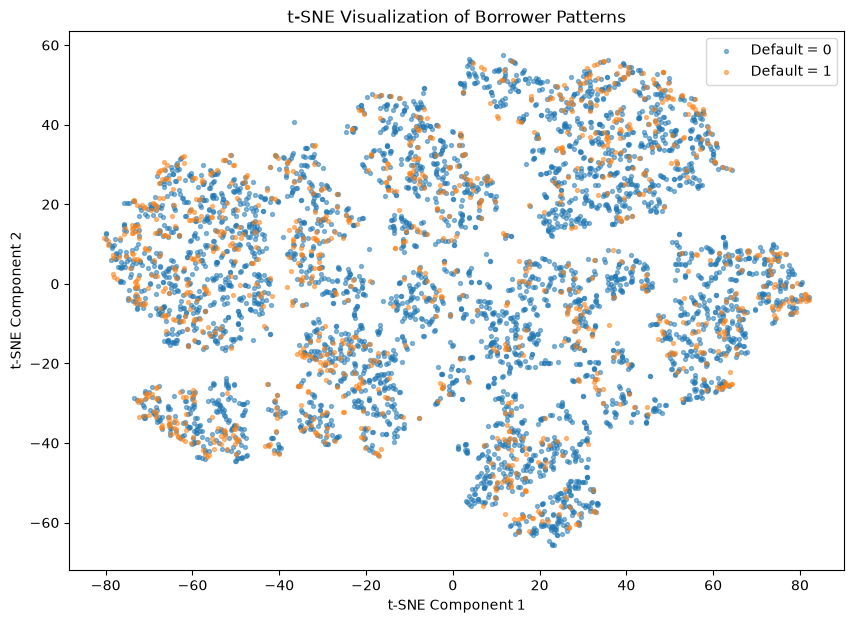

In [10]:
plt.figure(figsize=(10, 7))

for label, color in [(0, 'blue'), (1, 'red')]:
    mask = default_labels == label

    plt.scatter(
        X_tsne[mask, 0],
        X_tsne[mask, 1],
        label=f'Default = {label}',
        color=color,
        alpha=0.5,
        s=8
    )

plt.title('t-SNE Visualization of Borrower Patterns')
plt.xlabel('t-SNE Component 1')
plt.ylabel('t-SNE Component 2')
plt.legend()
plt.show()

## Step 5.3 – UMAP visualization (optional alternative)

UMAP is another dimensionality-reduction method that is useful for exploring local and broader data structure. It is run on the same 5,000-record PCA sample as t-SNE.

In [ ]:
# Run once if umap-learn is not installed:
# %pip install umap-learn

In [12]:
import umap

umap_model = umap.UMAP(
    n_components=2,
    n_neighbors=15,
    min_dist=0.1,
    metric='euclidean',
    random_state=42
)

X_umap = umap_model.fit_transform(X_sample_pca)

print("UMAP output shape:", X_umap.shape)

C:\Users\VIDYAPRIYA V\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\LocalCache\local-packages\Python313\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


UMAP output shape: (5000, 2)


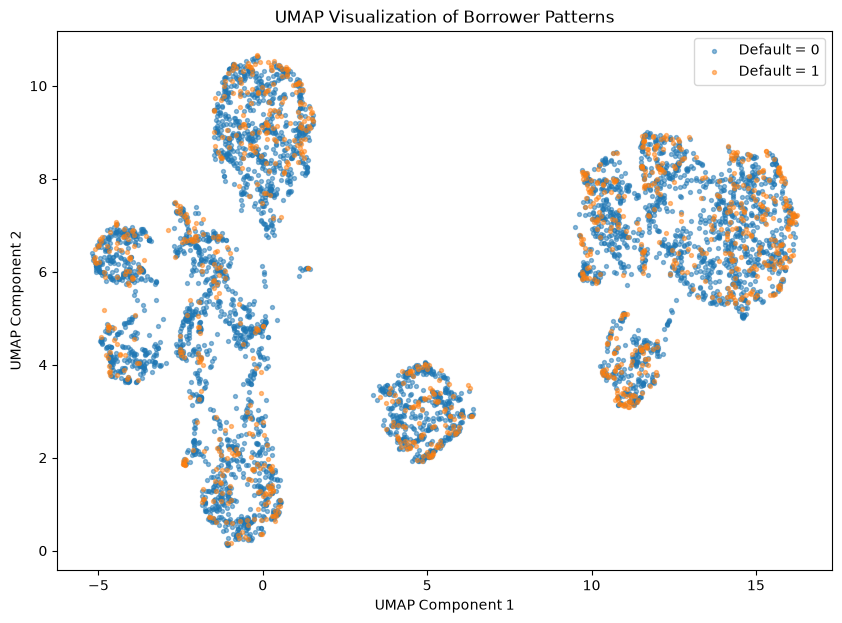

In [14]:
plt.figure(figsize=(10, 7))

for label, color in [(0, 'blue'), (1, 'red')]:
    mask = default_labels == label

    plt.scatter(
        X_umap[mask, 0],
        X_umap[mask, 1],
        label=f'Default = {label}',
        color=color,
        alpha=0.5,
        s=8
    )

plt.title('UMAP Visualization of Borrower Patterns')
plt.xlabel('UMAP Component 1')
plt.ylabel('UMAP Component 2')
plt.legend()
plt.show()

### Progress so far

- PCA was applied to 1,347,681 records, reducing 34 features to 10 components.
- 88.95% of the total variance was retained.
- t-SNE and UMAP were applied to a 5,000-record sample.

The 2D plots are for exploration only and are not required for the next step.

## Step 5.4 – Validate dimensionality-reduction outputs

In [15]:
print("PCA shape:", X_pca.shape)
print("t-SNE shape:", X_tsne.shape)
print("UMAP shape:", X_umap.shape)

print("\nMissing values:")
print("PCA:", np.isnan(X_pca).sum())
print("t-SNE:", np.isnan(X_tsne).sum())
print("UMAP:", np.isnan(X_umap).sum())

PCA shape: (1347681, 10)
t-SNE shape: (5000, 2)
UMAP shape: (5000, 2)

Missing values:
PCA: 0
t-SNE: 0
UMAP: 0


## Step 5.5 – Final results

| Method | Input records | Output dimensions | Status |
|---|---|---|---|
| PCA (Incremental PCA) | 1,347,681 | 10 | Successful |
| t-SNE | 5,000 | 2 | Successful |
| UMAP | 5,000 | 2 | Successful |

**Key findings**

1. PCA: reduced 34 features to 10 components while retaining 88.95% of the variance.
2. t-SNE: converted the 10-dimensional PCA representation into a 2D representation for visual exploration.
3. UMAP: also generated a 2D representation, providing another way to explore borrower patterns.
4. Data quality: no missing values were found in any dimensionality-reduction output.

**Documentation notes**

- PCA was performed on the complete dataset.
- t-SNE and UMAP were performed on the same 5,000-record sample.
- `Default` was excluded from all dimensionality-reduction inputs and used only for colouring the plots.
- t-SNE and UMAP embeddings are visualization aids, not evidence of confirmed borrower clusters.

**Conclusion**

Dimensionality reduction was completed. The dataset is represented by a 10-component PCA output for the full population and by 2D t-SNE/UMAP embeddings for a sample.